# 📊 Credit Card Delinquency Rate Forecasting using ARIMA

This project analyzes and forecasts credit card delinquency rates using time series techniques. The objective is to understand historical trends, build a forecasting model, and simulate stress scenarios relevant for risk management in banking.

## 📌 Introduction

Delinquency rate refers to the percentage of borrowers who fail to make required payments on time. It is a critical metric for financial institutions to monitor credit risk.

In this project, we analyze historical credit card delinquency data and build a time series forecasting model using ARIMA. Additionally, we simulate stress scenarios to understand how delinquency may behave under adverse economic conditions.

## 📂 Dataset Description

The dataset contains historical observations of credit card delinquency rates.

- **observation_date**: Date of observation
- **DRCCLACBS (drcclac)**: Delinquency rate (%)

The data is recorded over time, making it suitable for time series analysis.

## 🎯 Objective

The main objectives of this project are:

- To analyze trends and patterns in delinquency rates
- To check stationarity of the time series
- To transform the data if required
- To build an ARIMA model for forecasting
- To simulate stress scenarios for risk analysis

In [1]:
import pandas as pd

In [2]:
df=pd.read_csv('ccdr_usa.csv')
df.head()

,observation_date,DRCCLACBS
0,1991-01-01,5.26
1,1991-04-01,5.48
2,1991-07-01,5.35
3,1991-10-01,5.32
4,1992-01-01,5.27


In [3]:
df['observation_date']= pd.to_datetime(df['observation_date'])
df.set_index('observation_date', inplace= True)

In [4]:
df.head()

,DRCCLACBS
observation_date,
1991-01-01,5.26
1991-04-01,5.48
1991-07-01,5.35
1991-10-01,5.32
1992-01-01,5.27


In [6]:
df['DRCCLACBS'].mean()

np.float64(3.6916312056737586)

In [28]:
import matplotlib.pyplot as plt

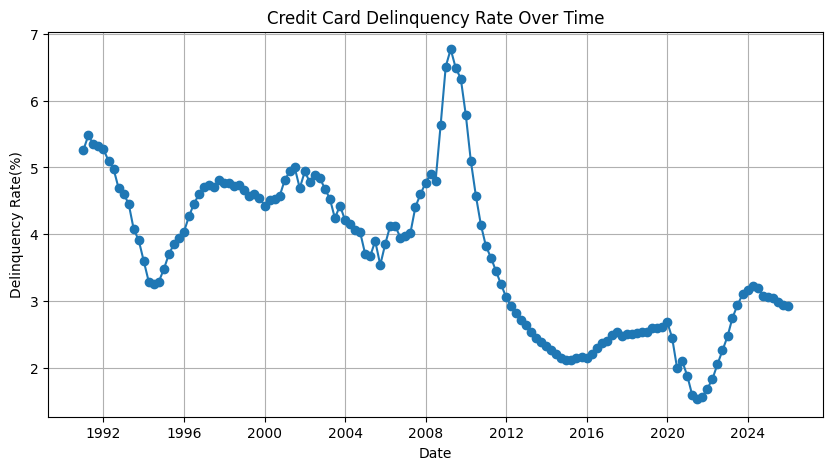

In [29]:
plt.figure(figsize=(10,5))
plt.plot(df['DRCCLACBS'], marker='o')
plt.title('Credit Card Delinquency Rate Over Time')
plt.xlabel('Date')
plt.ylabel('Delinquency Rate(%)')
plt.grid()
plt.show()

## 📈 Time Series Visualization

The delinquency rate is plotted over time to observe trends, patterns, and unusual spikes.

### Key Observations:
- A major spike is observed around 2008–2009, corresponding to the global financial crisis
- After 2010, the delinquency rate shows a declining trend
- The series appears non-stationary due to trend changes over time

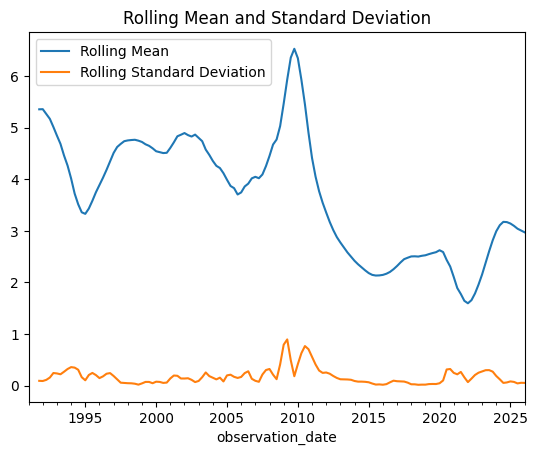

In [30]:
df['DRCCLACBS'].rolling(window=4).mean().plot(label='Rolling Mean')
df['DRCCLACBS'].rolling(window=4).std().plot(label='Rolling Standard Deviation')
plt.legend()
plt.title('Rolling Mean and Standard Deviation')
plt.show()

## 📊 Rolling Mean and Rolling Standard Deviation

Rolling statistics help us understand whether the mean and variance of the series are constant over time.

### Interpretation:
- If rolling mean and standard deviation change over time → non-stationary
- In our case, both vary → the series is non-stationary

In [31]:
from statsmodels.tsa.stattools import adfuller
result= adfuller(df['DRCCLACBS'])
print(result)
print('ADF Statistic:', result[0])
print('p-value:', result[1])

(np.float64(-2.324084482899511), np.float64(0.16431785237841345), 2, 138, {'1%': np.float64(-3.47864788917503), '5%': np.float64(-2.882721765644168), '10%': np.float64(-2.578065326612056)}, np.float64(-71.2655376701779))
ADF Statistic: -2.324084482899511
p-value: 0.16431785237841345


##  Augmented Dickey-Fuller (ADF) Test

The ADF test is used to check whether the time series is stationary.

### Hypotheses:
- H₀: Series is non-stationary
- H₁: Series is stationary

### Result:
- p-value > 0.05 → fail to reject H₀
- Therefore, the series is non-stationary

<Axes: title={'center': 'First Differenced Series'}, xlabel='observation_date'>

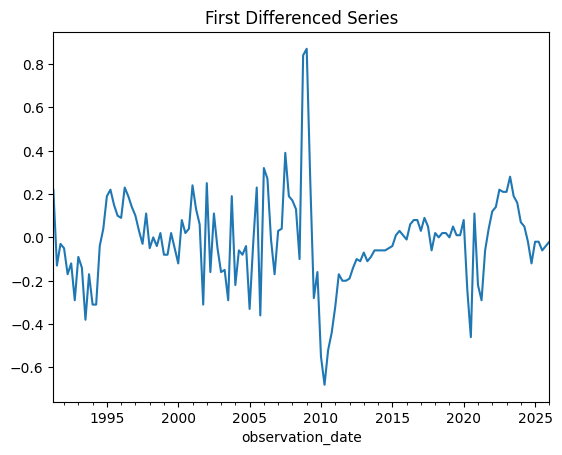

In [32]:
df['diff']= df['DRCCLACBS'].diff()
df['diff'].dropna().plot(title='First Differenced Series')

##  Differencing

To make the series stationary, we apply first-order differencing:

Zₜ = Yₜ − Yₜ₋₁

### Intuition:
- Removes trend
- Converts data into "change in delinquency rate"
- Helps stabilize the mean

After differencing, the series fluctuates around a constant level.

In [33]:
from statsmodels.tsa.stattools import adfuller
result_diff= adfuller(df['diff'].dropna())
print(result_diff)
print('ADF Statistic:', result_diff[0])
print('p-value:', result_diff[1])

(np.float64(-4.377513324406802), np.float64(0.00032524604795981874), 11, 128, {'1%': np.float64(-3.4825006939887997), '5%': np.float64(-2.884397984161377), '10%': np.float64(-2.578960197753906)}, np.float64(-69.84390089842839))
ADF Statistic: -4.377513324406802
p-value: 0.00032524604795981874


##  ADF Test After Differencing

After applying first differencing:

- p-value < 0.05 → reject H₀
- The series is now stationary

This confirms that differencing was successful.

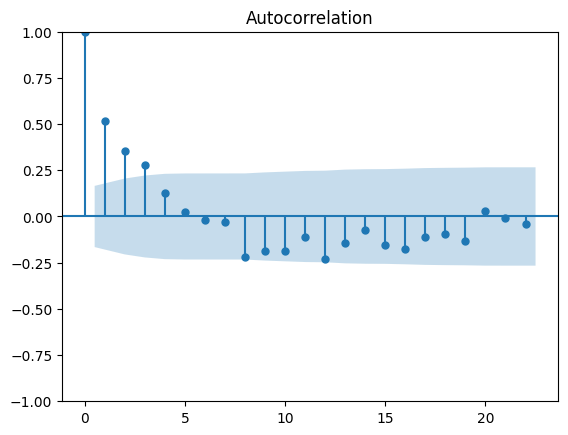

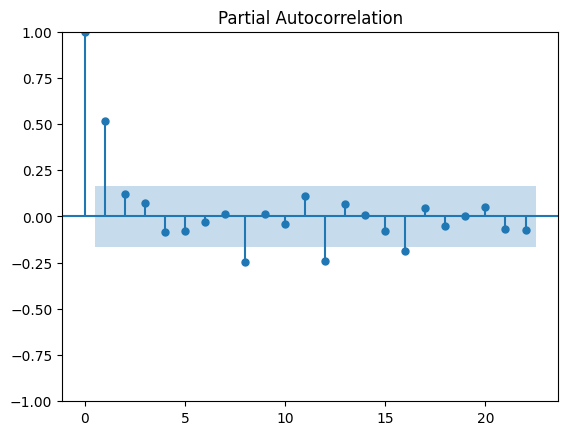

In [34]:
from statsmodels.graphics.tsaplots import plot_acf , plot_pacf
plot_acf(df['diff'].dropna())
plot_pacf(df['diff'].dropna())
plt.show()

##  ACF and PACF Analysis

ACF and PACF plots help determine the parameters of the ARIMA model.

### Observations:
- ACF shows gradual decay → indicates AR component
- PACF cuts off after lag 1 → suggests p = 1
- Some minor patterns suggest inclusion of MA component

### Conclusion:
Candidate models:
- ARIMA(1,1,0)
- ARIMA(1,1,1)

In [35]:
from statsmodels.tsa.arima.model import ARIMA

models = [
    (1,1,0),
    (2,1,0),
    (1,1,1),
    (2,1,1)
]

for order in models:
    model = ARIMA(df['DRCCLACBS'], order=order)
    result = model.fit()
    print(f"ARIMA{order} AIC:", result.aic)

C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred fre

ARIMA(1, 1, 0) AIC: -80.90960781952052
ARIMA(2, 1, 0) AIC: -80.87234558026122
ARIMA(1, 1, 1) AIC: -81.11447282304718


C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


ARIMA(2, 1, 1) AIC: -79.12508215413578


##  Model Selection using AIC

AIC (Akaike Information Criterion) helps select the best model.

- Lower AIC → better model

### Result:
ARIMA(1,1,1) has the lowest AIC

### Conclusion:
ARIMA(1,1,1) is selected as the final model

##  Model Interpretation

ARIMA(1,1,1) means:

- p = 1 → depends on 1 past value
- d = 1 → first differencing applied
- q = 1 → depends on 1 past error

### Intuition:
The change in delinquency rate depends on:
- previous change (AR component)
- previous shock/error (MA component)

### Model Validation Approach

To evaluate the forecasting performance, the dataset was split into training and testing sets using an 80-20 split.

The model was trained on historical data (training set) and evaluated on unseen future observations (test set), simulating a real-world forecasting scenario.

In [36]:
# Train-Test Split (80-20)
train_size = int(len(df['DRCCLACBS']) * 0.8)

train = df['DRCCLACBS'][:train_size]
test = df['DRCCLACBS'][train_size:]

In [37]:
from statsmodels.tsa.arima.model import ARIMA

model = ARIMA(train, order=(1,1,1))
result = model.fit()

print(result.summary())

                               SARIMAX Results                                
Dep. Variable:              DRCCLACBS   No. Observations:                  112
Model:                 ARIMA(1, 1, 1)   Log Likelihood                  28.909
Date:                Wed, 09 Sep 2026   AIC                            -51.818
Time:                        13:01:33   BIC                            -43.689
Sample:                    01-01-1991   HQIC                           -48.520
                         - 10-01-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.6754      0.098      6.891      0.000       0.483       0.867
ma.L1         -0.2169      0.109     -1.985      0.047      -0.431      -0.003
sigma2         0.0347      0.003     13.171      0.0

C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


### Model Diagnostics

The ARIMA(1,1,1) model parameters are statistically significant, indicating meaningful relationships with past values and error terms.

- Ljung-Box Test (p = 0.93): Residuals show no autocorrelation, suggesting a good model fit.
- Jarque-Bera Test (p = 0.00): Residuals are not normally distributed, indicating the presence of extreme values or shocks.
- Heteroskedasticity Test (p = 0.84): Variance of residuals is stable.

These results indicate that while the model captures the underlying structure well, it is sensitive to extreme events.

In [38]:
forecast = result.forecast(steps=len(test))

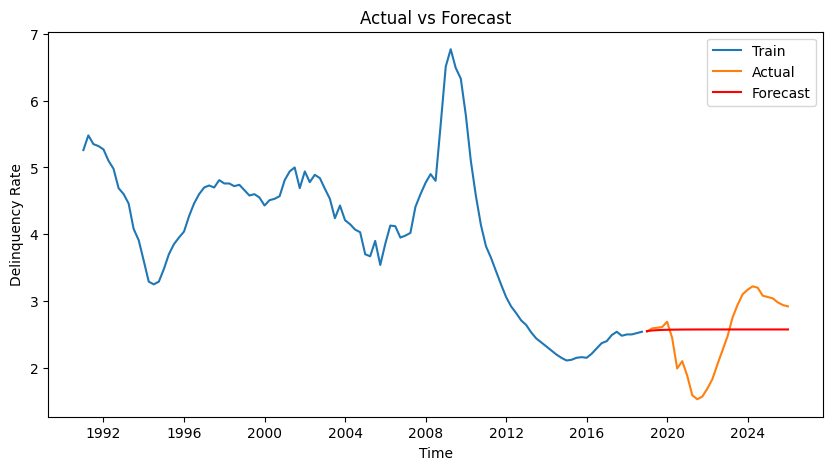

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(train, label='Train')
plt.plot(test, label='Actual')
plt.plot(test.index, forecast, label='Forecast', color='red')

plt.title("Actual vs Forecast")
plt.xlabel("Time")
plt.ylabel("Delinquency Rate")
plt.legend()

plt.show()

### Forecast vs Actual Comparison

The model’s forecasts were compared against actual observed values in the test set.

The ARIMA model captures the overall trend in delinquency rates; however, it produces relatively smooth forecasts and does not fully capture sudden fluctuations in the data.

This behavior is expected, as ARIMA models are designed to model underlying patterns rather than abrupt structural changes.

In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 0.4559178810972788
RMSE: 0.5443381148664844


### Forecast Accuracy Metrics

To quantify model performance, the following metrics were computed:

- Mean Absolute Error (MAE): 0.456  
- Root Mean Squared Error (RMSE): 0.544  

Given the scale of delinquency rates, these errors indicate that the model provides a reasonable approximation of the underlying trend, though deviations occur during volatile periods.

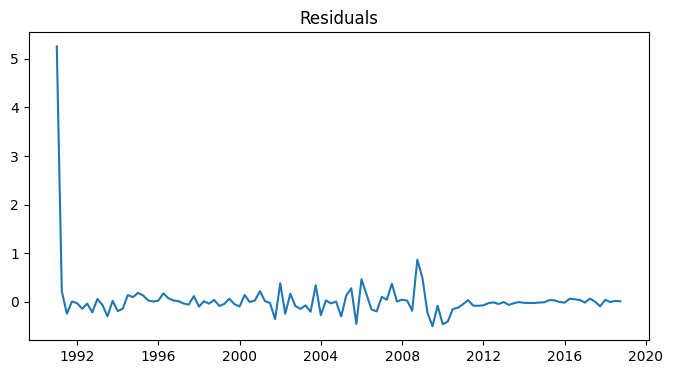

In [41]:
residuals = result.resid

plt.figure(figsize=(8,4))
plt.plot(residuals)
plt.title("Residuals")
plt.show()

### Residual Analysis

Residuals were analyzed to assess model adequacy.

The residuals are largely centered around zero and exhibit no clear pattern, suggesting that the model has successfully captured the time-dependent structure of the data.

However, occasional large spikes are observed, indicating the presence of outliers or structural shocks that are not well captured by the model.

C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)
C:\Users\Saleena\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency QS-OCT will be used.
  self._init_dates(dates, freq)


2026-04-01    2.905052
2026-07-01    2.894792
2026-10-01    2.887750
2027-01-01    2.882917
2027-04-01    2.879599
2027-07-01    2.877322
2027-10-01    2.875759
2028-01-01    2.874686
Freq: QS-OCT, Name: predicted_mean, dtype: float64


<Axes: title={'center': 'Forecasted Delinquency Rate'}>

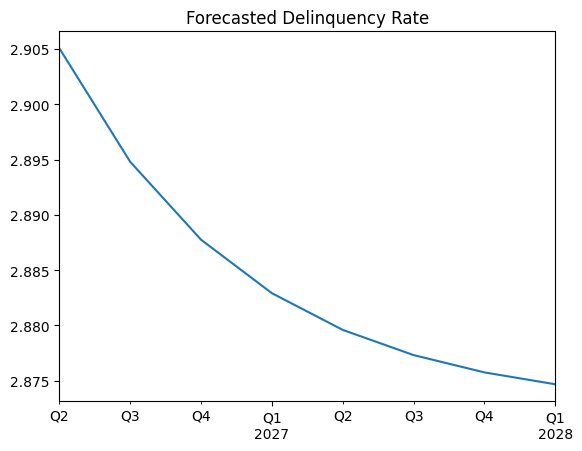

In [42]:
model = ARIMA(df['DRCCLACBS'], order=(1,1,1))
result = model.fit()

forecast = result.forecast(steps=8)

print(forecast)

forecast.plot(title="Forecasted Delinquency Rate")

##  Forecasting Future Delinquency Rate

The model is used to forecast future delinquency rates.

### Observations:
- Forecast appears relatively stable
- Slight declining behavior is observed
- No extreme spikes expected under normal conditions

##  Stress Testing Scenario

To simulate adverse economic conditions, a stress scenario is applied.

### Interpretation:
- Delinquency rate increases under stress
- Helps understand worst-case risk
- Useful for banking risk management and capital planning

In [43]:
forecast = result.forecast(steps=8)

In [44]:
stress_forecast = forecast.copy()

# Add shock (increase delinquency artificially)
stress_forecast = stress_forecast + 0.5

In [45]:
import numpy as np
shock = np.linspace(0.1, 0.5, len(forecast))
stress_forecast = forecast + shock

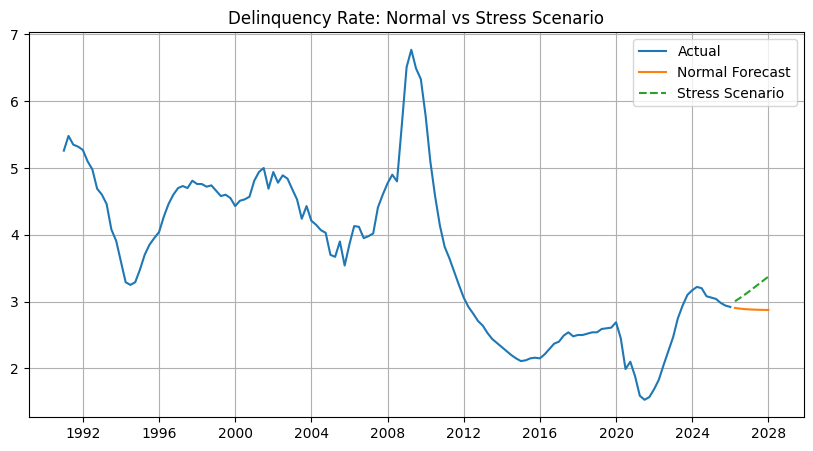

In [46]:
plt.figure(figsize=(10,5))

plt.plot(df.index, df['DRCCLACBS'], label='Actual')
plt.plot(forecast.index, forecast, label='Normal Forecast')
plt.plot(stress_forecast.index, stress_forecast, label='Stress Scenario', linestyle='--')

plt.legend()
plt.title('Delinquency Rate: Normal vs Stress Scenario')
plt.grid()
plt.show()

### Conclusion

In this project, an ARIMA(1,1,1) model was developed to forecast U.S. credit card delinquency rates. The model successfully captured the underlying trend and temporal dependence in the data, as confirmed by statistical diagnostics such as the Ljung-Box test.

Model validation using a train-test split showed reasonable predictive performance (RMSE ≈ 0.54), indicating that the model provides a good approximation of long-term behavior.

However, the analysis also revealed important limitations. The model struggled to capture sudden structural shocks, such as the COVID-19 period, which was further supported by non-normal residuals and observed forecast deviations.

To address this, stress testing scenarios were incorporated to evaluate potential outcomes under adverse conditions, making the analysis more relevant from a risk management perspective.

Overall, the project demonstrates both the strengths and limitations of ARIMA models in real-world financial time series forecasting, highlighting the importance of combining statistical models with scenario-based analysis.